#1. Part 1 - Synthetic Experimentation

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import minimize
import math
import functools
import operator
import time
from tqdm import tqdm
import os
import random
import itertools
from typing import List, Tuple

random.seed(42)
np.random.seed(42)


##1.1 - preparations

In [4]:
def nyse_n(folder_path):
    """
    Reads CSV files from the specified folder and returns a DataFrame with 21 columns and 5526 rows,
    where each column is named after its corresponding CSV file (without the .csv extension),
    and contains data from rows 5652 to 11177.

    Parameters:
    folder_path (str): The path to the folder containing the CSV files.

    Returns:
    pd.DataFrame: The processed DataFrame.
    """
    # List to hold each column of data and their corresponding column names
    data_columns = []
    column_names = []

    # Get a sorted list of CSV files in the folder to ensure consistent column order
    csv_files = sorted([f for f in os.listdir(folder_path) if f.endswith('.csv')])

    # Check that there are exactly 21 CSV files
    if len(csv_files) != 21:
        raise ValueError(f"Expected 21 CSV files, but found {len(csv_files)}.")

    # Loop through each CSV file
    for file_name in csv_files:
        file_path = os.path.join(folder_path, file_name)

        # Read the CSV file
        df = pd.read_csv(file_path, header=None)

        # Check if the CSV file has at least two columns
        if df.shape[1] < 2:
            raise ValueError(f"File {file_name} does not have at least two columns.")

        # Extract the second column (index 1)
        second_column = df.iloc[:, 1].astype(float).reset_index(drop=True)

        # Append the column to the list
        data_columns.append(second_column)

        # Extract the file name without the '.csv' extension to use as column name
        column_name = os.path.splitext(file_name)[0]
        column_names.append(column_name)

    # Combine all columns into a DataFrame
    combined_df = pd.concat(data_columns, axis=1)

    # Set the column names based on the file names
    combined_df.columns = column_names

    # Check if the DataFrame has the expected number of rows
    if combined_df.shape[0] != 11178:
        raise ValueError("The combined DataFrame does not have 11178 rows.")

    # Slice the DataFrame to keep rows from index 5652 to 11177 (zero-based indexing)
    processed_df = combined_df.iloc[5651:11178].reset_index(drop=True)

    # Return the processed DataFrame
    return processed_df

def load_and_construct_nyseo_dataframe(file_path, num_columns):
    column_names = [str(i) for i in range(1, num_columns + 1)]
    df = pd.read_csv(file_path, delimiter='\s+', header=None, names=column_names)
    return df
def extract_columns(df, x, y):
    new_df = df[[str(x), str(y)]]
    return new_df

########## NYSE(O) ##########
folder_path_nyseo = './NYSE(O).txt'
df_O = load_and_construct_nyseo_dataframe(folder_path_nyseo, 36)
print("\nDataFrame with row ids from 1 to K: \n", df_O)

comb1_2_stocks = [20, 23] # Iroquois & Kin_Ark
comb2_2_stocks = [6, 23] # Comm_Metals & Kin_Ark
comb3_2_stocks = [6, 26] # Comm_Metals & Meicco
comb1_3_stocks = ["25", "23", "4"]
comb2_3_stocks = ["35", "13", "23"]
comb3_3_stocks = ["16", "9", "32"]

# [NYSEO] comb 1-3, extensive in UP, EG, etc.
comb1_two = extract_columns(df_O, comb1_2_stocks[0], comb1_2_stocks[1])
comb2_two = extract_columns(df_O, comb2_2_stocks[0], comb2_2_stocks[1])
comb3_two = extract_columns(df_O, comb3_2_stocks[0], comb3_2_stocks[1])
# [NYSEO] comb 4-6, used in Yang et al..
comb4_three = df_O[comb1_3_stocks]
comb5_three = df_O[comb2_3_stocks]
comb6_three = df_O[comb3_3_stocks]


DataFrame with row ids from 1 to K: 
             1        2        3        4        5        6        7        8  \
0     1.01515  1.02765  1.04183  1.02083  1.00637  1.04938  1.00847  1.01983   
1     1.01493  1.04036  0.98905  0.99490  1.00475  0.95294  1.00840  1.00833   
2     1.00000  0.97629  0.97786  0.99744  0.98583  0.98765  0.99722  0.99449   
3     1.02451  1.00662  1.02642  1.00257  1.01917  1.00000  0.99443  1.00693   
4     1.03100  0.98465  1.00368  1.00513  1.00313  1.05000  1.02801  1.00413   
...       ...      ...      ...      ...      ...      ...      ...      ...   
5646  1.00980  1.01027  1.00394  1.00867  1.00402  1.00000  0.99381  1.00000   
5647  1.00000  0.99661  0.99216  1.00000  0.99200  1.00000  0.99548  0.99478   
5648  0.99029  0.99660  0.99605  1.00573  0.99798  1.00000  0.99091  1.01050   
5649  0.99265  1.00683  1.00000  1.00855  1.00808  1.00514  0.99541  1.01299   
5650  0.99753  1.00339  1.01984  0.99718  1.00000  0.99286  1.01382  1.01538   



<>:63: SyntaxWarning: invalid escape sequence '\s'
<>:63: SyntaxWarning: invalid escape sequence '\s'
/tmp/ipython-input-1920755287.py:63: SyntaxWarning: invalid escape sequence '\s'
  df = pd.read_csv(file_path, delimiter='\s+', header=None, names=column_names)


In [5]:
########## NYSE(N) ##########
folder_path_nysen = "./NYSE(N)"
df_N = nyse_n(folder_path_nysen)

# Mock df_N with placeholder numbers (remove this block in real usage)
columns = ['Bond', 'Cash', 'ahp', 'alcoa', 'amerb', 'coke', 'dow', 'dupont',
           'ford', 'ge', 'gm', 'hp', 'ibm', 'inger', 'jnj', 'kimbc', 'merck',
           'mmm', 'morris', 'pandg', 'schlum']

asset_cols = [c for c in df_N.columns if c not in ('Bond', 'Cash')]

# 1) comb7_5 : 5 random asset columns
comb7_5_cols = random.sample(asset_cols, 5)
comb7_5 = df_N[comb7_5_cols]

# 2) comb8_5 : 5 other columns disjoint from comb7_5
remaining_after_7 = [c for c in asset_cols if c not in comb7_5_cols]
comb8_5_cols = random.sample(remaining_after_7, 5)
comb8_5 = df_N[comb8_5_cols]

# 3) comb9_8 : 8 random asset columns
comb9_8_cols = random.sample(asset_cols, 8)
comb9_8 = df_N[comb9_8_cols]

# 4) comb10_8 : 8 other columns disjoint from comb9_8
remaining_after_9 = [c for c in asset_cols if c not in comb9_8_cols]
comb10_8_cols = random.sample(remaining_after_9, 8)
comb10_8 = df_N[comb10_8_cols]

# 5) comb11_11 : 11 random asset columns
comb11_11_cols = random.sample(asset_cols, 11)
comb11_11 = df_N[comb11_11_cols]

# 6) comb12_11 : must include every asset not in comb11_11, then fill to 11
leftover = [c for c in asset_cols if c not in comb11_11_cols]
extra_needed = 11 - len(leftover)
extra_cols = random.sample(comb11_11_cols, extra_needed) if extra_needed > 0 else []
comb12_11_cols = leftover + extra_cols
comb12_11 = df_N[comb12_11_cols]

# Show the selected column names for verification
print("comb7_5 cols :", comb7_5_cols)
print("comb8_5 cols :", comb8_5_cols)
print("comb9_8 cols :", comb9_8_cols)
print("comb10_8 cols:", comb10_8_cols)
print("comb11_11 cols:", comb11_11_cols)
print("comb12_11 cols:", comb12_11_cols)

# comb1_two,comb2_two,comb3_two,comb4_three,comb5_three,comb6_three
# comb7_5, comb8_5, comb9_8, comb10_8, comb11_11, comb12_11

comb7_5 cols : ['coke', 'ahp', 'gm', 'ge', 'schlum']
comb8_5 cols : ['dow', 'mmm', 'amerb', 'merck', 'jnj']
comb9_8 cols : ['amerb', 'kimbc', 'alcoa', 'ahp', 'morris', 'coke', 'pandg', 'gm']
comb10_8 cols: ['mmm', 'dow', 'merck', 'ge', 'ibm', 'inger', 'hp', 'jnj']
comb11_11 cols: ['ge', 'merck', 'gm', 'ahp', 'jnj', 'pandg', 'amerb', 'inger', 'ford', 'dupont', 'dow']
comb12_11 cols: ['alcoa', 'coke', 'hp', 'ibm', 'kimbc', 'mmm', 'morris', 'schlum', 'gm', 'ahp', 'pandg']


##1.2 - utilities

In [6]:
def bcrp(df):
    ratio_matrix = df.values  # Shape: (Time Steps, Assets)
    N = ratio_matrix.shape[1]  # Number of assets

    def objective(weights):
        # Calculate portfolio returns over time
        V = np.dot(ratio_matrix, weights)
        # Ensure no zero or negative values in V to avoid log(0) or log of negative numbers
        if np.any(V <= 0):
            return np.inf  # Penalize invalid weights leading to non-positive returns
        # Calculate cumulative log return
        log_V = np.log(V)
        CR = np.sum(log_V)
        return -CR  # Negative sign because we are minimizing

    # Constraints: weights sum to 1
    constraints = {'type': 'eq', 'fun': lambda weights: np.sum(weights) - 1}
    # Bounds: weights between 0 and 1
    bounds = [(0, 1) for _ in range(N)]
    # Initial guess: equally distributed weights
    initial_guess = np.ones(N) / N

    # Optimize using SLSQP (Sequential Least Squares Programming)
    result = minimize(
        objective,
        initial_guess,
        method='SLSQP',
        bounds=bounds,
        constraints=constraints,
        options={'disp': False}
    )

    if not result.success:
        print("Optimization failed:", result.message)
        return None

    optimal_weights = result.x
    dot_product_result = df.values @ optimal_weights
    wealth = np.prod(dot_product_result)

    # print(f"\nBCRP Wealth:{wealth}")
    # print(f"Optimal weights: {optimal_weights}")
    return optimal_weights, wealth

def opt(df: pd.DataFrame) -> float:
    top_values = df.max(axis=1)
    final_wealth = top_values.prod()
    return final_wealth

def adv(df: pd.DataFrame) -> float:
    top_values = df.min(axis=1)
    final_wealth = top_values.prod()
    return final_wealth

def ucrp(df):
  # Convert DataFrame to numpy array
  price_relatives = df.values
  num_steps, num_assets = price_relatives.shape
  # Initialize portfolio weights (uniform distribution)
  weights = np.ones(num_assets) / num_assets
  # Initialize portfolio value
  portfolio_values = np.ones(num_steps)

  # Iterate through each time step
  cur_wealth = 1
  for t in range(num_steps):
    # Calculate the portfolio value at the current time step
    portfolio_values[t] = np.dot(weights, price_relatives[t])
    # get current wealth
    sum = 0
    for i,j in zip(weights, price_relatives[t]):
      sum += i * j
    cur_wealth = cur_wealth * sum
    # Update the weights based on the price relatives
    weights = (weights * price_relatives[t]) / np.dot(weights, price_relatives[t])
  return cur_wealth

def am(df):
    price_relatives = df.values  # shape = (T, N)
    T, N = price_relatives.shape

    # Initial weights for uniform buy-and-hold
    weights = np.ones(N) / N

    # Each asset’s cumulative product of price relatives
    # => how much each $1 in that asset grows over time
    cumulative_growth = np.cumprod(price_relatives, axis=0)  # shape = (T, N)

    # At the final time step (T-1), the value of the portfolio is
    # sum_i [ initial_fraction_in_asset_i * cumulative_growth(T-1, i) ]
    final_wealth = np.sum(weights * cumulative_growth[-1, :])
    return final_wealth

def best(df):
    # Convert DataFrame to NumPy array: shape = (T, N)
    price_relatives = df.values
    # Initialize wealth for each stock
    # wealth[i] will hold the product of all price relatives for stock i
    _, num_assets = price_relatives.shape
    wealth = np.ones(num_assets)
    # Accumulate final wealth for each single-stock buy-and-hold
    for row in price_relatives:
        wealth *= row  # multiply each stock's wealth by that stock's price relative at this time step
    # Pick the best single stock (largest final wealth)
    return wealth.max()  # same as wealth[np.argmax(wealth)]

def worst(df):
    # Convert DataFrame to NumPy array: shape = (T, N)
    price_relatives = df.values
    # Initialize wealth for each stock
    # wealth[i] will hold the product of all price relatives for stock i
    _, num_assets = price_relatives.shape
    wealth = np.ones(num_assets)
    # Accumulate final wealth for each single-stock buy-and-hold
    for row in price_relatives:
        wealth *= row  # multiply each stock's wealth by that stock's price relative at this time step
    # Pick the best single stock (largest final wealth)
    return wealth.min()  # same as wealth[np.argmax(wealth)]

def gm(df):
    # Convert to a NumPy array for convenience
    arr = df.values  # shape = (T, N)
    # final_wealth[i] = product of all price relatives for asset i
    final_wealths = arr.prod(axis=0)  # shape = (N,)
    # geometric mean of these final wealths
    gm_value = np.prod(final_wealths) ** (1.0 / len(final_wealths))
    return gm_value

def generate_simplex(m, step_size=0.01):
    """
    Generate all m-dimensional weight vectors (w1,...,wm) with increments step_size
    such that sum(wi) = 1. Returns a list of lists of length m.
    """
    def dfs(dim, total):
        if dim == 1:
            yield [total]
        else:
            steps = int(round(total / step_size))
            for i in range(steps + 1):
                w = i * step_size
                for rest in dfs(dim - 1, total - w):
                    yield [w] + rest

    return list(dfs(m, 1.0))

def up(df, step_size=0.01, plot=False):
    """
    Computes the Universal Portfolio using a discrete set of weight vectors
    on the simplex with granularity 'step_size'.

    df: A pandas DataFrame of prices/returns, shape (T, m)
    step_size: The increment for generating the simplex.

    Returns:
        to_plot: The log wealth over time (list of length T+1)
        cur_wealth: Final wealth (scalar)
    """
    # 1) Enumerate the simplex
    simplex_list = generate_simplex(df.shape[1], step_size)
    # Convert to a NumPy array of shape (N, m)
    simplex = np.array(simplex_list, dtype=np.float64)
    N = simplex.shape[0]

    # 2) Initialize each combination's cumulative performance
    cumulative_simplex = np.ones(N, dtype=np.float64)

    # 3) Initialize portfolio weights (e.g. uniform)
    m = df.shape[1]
    weights = np.ones(m, dtype=np.float64) / m

    to_plot = [0.0]     # we keep track of log-wealth
    cur_wealth = 1.0    # actual wealth

    # Convert df to NumPy for faster iteration
    data = df.values

    for t in range(len(data)):
        row = data[t, :]  # shape (m,)

        # (A) Compute current portfolio return
        ret_t = weights @ row  # dot product
        cur_wealth *= ret_t
        # log-wealth
        to_plot.append(to_plot[-1] + np.log(ret_t))

        # (B) Update each weight vector's performance
        #     payoff_j = sum_j ( w_j[i] * row[i] )
        payoff = simplex @ row  # shape (N,)
        cumulative_simplex *= payoff

        # (C) Compute the new mixture distribution
        #     (the probability of each weight vector)
        total_perf = cumulative_simplex.sum()
        performance = cumulative_simplex / total_perf  # shape (N,)

        # (D) Derive the new portfolio by mixing over all weight vectors
        #     weights[i] = sum_j (performance_j * simplex[j, i])
        #     which is a matrix multiplication
        weights = performance @ simplex  # shape (m,)

    return to_plot, cur_wealth

def eg(df, eta, plot=False):
  weights = [1/df.shape[1] for i in range(df.shape[1])]
  cur_wealth = 1
  to_plot = [0]
  for _, row in df.iterrows():
    stock_vector = row.to_list()

    #compute current wealth
    sum = 0
    for i,j in zip(weights, stock_vector):
      sum += i * j
    cur_wealth = cur_wealth * sum
    #compute cumulative return of current weights
    dR = np.log(sum)
    to_plot.append(to_plot[-1]+dR)

    sum = 0
    for idx, i in enumerate(stock_vector):
      sum += weights[idx]*i

    for idx in range(len(weights)):
      weights[idx] = weights[idx]*math.exp(eta*stock_vector[idx]/sum)
    sum = np.sum(weights)

    for idx in range(len(weights)):
      weights[idx] = weights[idx]/sum

  print(f"Total accumulated wealth is: {cur_wealth}")
  print(f"Final Cumulative Lograthimic Wealth: {to_plot[-1]}")
  print(weights)
  if plot:
    plt.figure(figsize=(20, 8))
    plt.plot(to_plot)
    # plt.plot(comb1.iloc[:, 0].tolist())
    # plt.plot(comb1.iloc[:, 1].tolist())
    plt.grid(True)
    plt.show()
  return to_plot, cur_wealth

def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)

def forecast_perm(values, p):
    n = len(values)
    asc  = sorted(range(n), key=lambda i: values[i])
    desc = asc[::-1]

    u = random.random()
    if p <= 0.5:
        if u < 1 - 2*p:                # Dirac on ascending
            return asc
        else:                           # uniform among n! perms
            return random.sample(asc, k=n)
    else:
        if u < 2*(1 - p):              # uniform block
            return random.sample(asc, k=n)
        else:                           # Dirac on descending
            return desc

def _simplex_grid(m, step):
    K = round(1.0 / step)
    partitions: List[Tuple[int, ...]] = []
    for cut_indices in itertools.combinations(range(K + m - 1), m - 1):
        parts = []
        last = -1
        for c in cut_indices + (K + m - 1,):
            parts.append(c - last - 1)
            last = c
        partitions.append(tuple(parts))
    grid = np.asarray(partitions, dtype=np.float64) / K
    return grid


def upsi(df, up_granularity):
    n, m = df.shape
    grid = _simplex_grid(m, up_granularity)
    G = grid.shape[0]
    wealth = np.ones((m, G), dtype=np.float64)
    state_tot = np.full(m, G, dtype=np.float64)
    algo_wealth = 1.0

    for _, row in df.iterrows():
        r_t = row.to_numpy(dtype=np.float64)         # (m,)

        # Side information revealed for this period
        s = 1 # random.randrange(m)                      # uniform in {0,…,m-1}

        # Update every grid portfolio *inside* state s
        gains = grid @ r_t                           # (G,)
        wealth[s] *= gains

        # Capital fraction residing in state s before / after update
        before = state_tot[s]
        after = wealth[s].sum()
        state_tot[s] = after

        # Only state-s capital is re-invested this round
        algo_wealth *= after / before

    return algo_wealth

import numpy as np

def ram_rand(df):
    n, m = df.shape
    cur_wealth = 1.0
    weights = np.ones(m) / m
    for _, row in df.iterrows():
        # clairvoyant return at i
        x = row.to_numpy(dtype=np.float64)
        # predicted return
        accuracy = 1
        y_idx = forecast_perm(x, accuracy)
        y = np.array([x[j] for j in y_idx])
        # permutation layer
        w_desc = np.sort(weights)[::-1]
        w_new = np.empty_like(weights)
        for rank, asset_idx in enumerate(y_idx):
            w_new[asset_idx] = w_desc[rank]
        # get wealth
        dR = w_new @ x
        cur_wealth *= dR
        # get new weights
        weights = (w_new * x) / dR
    return cur_wealth

def ram_upsi_rand(df, accuracy, up_granularity):
    n, m = df.shape
    # RAM init
    ram_wealth = 1.0
    weights = np.ones(m) / m

    # UPSI init
    grid = _simplex_grid(m, up_granularity)
    G = grid.shape[0]
    wealth = np.ones((m, G), dtype=np.float64)
    state_tot = np.full(m, G, dtype=np.float64)
    upsi_wealth = 1.0

    for _, row in df.iterrows():
        # clairvoyant return at i
        x = row.to_numpy(dtype=np.float64)

        # predicted return
        y_idx = forecast_perm(x, accuracy)
        y = np.array([x[j] for j in y_idx])
        s = y_idx[0]
        # permutation layer
        w_desc = np.sort(weights)[::-1]
        w_new = np.empty_like(weights)
        for rank, asset_idx in enumerate(y_idx):
            w_new[asset_idx] = w_desc[rank]
        # get wealth
        dR = w_new @ x
        ram_wealth *= dR
        # get new weights
        weights = (w_new * x) / dR

        ####### UPSI #########
        gains = grid @ x
        wealth[s] *= gains

        before = state_tot[s]
        after = wealth[s].sum()
        state_tot[s] = after
        upsi_wealth *= after / before

    return ram_wealth, upsi_wealth

def eg_with_states(df,eta):

    n, m = df.shape

    # one EG weight vector per state
    weights_eg = np.full((m, m), 1.0 / m, dtype=np.float64)
    wealth_eg  = 1.0

    for _, row in df.iterrows():
        x_t = row.to_numpy(dtype=np.float64)      # (m,)

        s = 1

        # ---- use & update only the active state's weights --------------------
        w_s      = weights_eg[s]
        port_ret = np.dot(w_s, x_t)
        wealth_eg  *= port_ret

        # Exponential-Gradient update
        w_s *= np.exp(eta * x_t / port_ret)
        w_s /= w_s.sum()

    return wealth_eg

def ram_eg_rand(df, accuracy, eta):
    n, m = df.shape
    # RAM init
    ram_wealth = 1.0
    weights = np.ones(m) / m

    # EG init
    weights_eg = np.full((m, m), 1.0 / m, dtype=np.float64)
    wealth_eg  = 1.0

    for _, row in df.iterrows():
        # clairvoyant return at i
        x = row.to_numpy(dtype=np.float64)

        # predicted return
        y_idx = forecast_perm(x, accuracy)
        y = np.array([x[j] for j in y_idx])
        s = y_idx[0]
        # permutation layer
        w_desc = np.sort(weights)[::-1]
        w_new = np.empty_like(weights)
        for rank, asset_idx in enumerate(y_idx):
            w_new[asset_idx] = w_desc[rank]
        # get wealth
        dR = w_new @ x
        ram_wealth *= dR
        # get new weights
        weights = (w_new * x) / dR

        ####### EG #########
        w_s      = weights_eg[s]
        port_ret = np.dot(w_s, x)
        wealth_eg  *= port_ret

        # Exponential-Gradient update
        w_s *= np.exp(eta * x / port_ret)
        w_s /= w_s.sum()

    return ram_wealth, wealth_eg

##1.3 - Table 1

In [ ]:
for i in [comb1_two,comb2_two,comb3_two,comb4_three,comb5_three,comb6_three]:
    gm_w = gm(i)
    _, up_w = up(i, 0.01)
    ram_adv = ram_rand(i)
    print(f"gm: {gm_w}, ram_adv: {ram_adv}, up: {up_w}")

In [ ]:
dataset = [comb1_two,comb2_two,comb3_two,comb4_three,comb5_three,comb6_three]

ram_list = [[],[],[],[],[],[]]
upsi_list = [[],[],[],[],[],[]]
accuracy = 0.5
set_seed(42)
runs = 1000

for idx,i in enumerate(dataset):
    for j in tqdm(range(runs)):
        ram_w, upsi_w = ram_upsi_rand(i, accuracy, 0.01)
        ram_list[idx].append(ram_w)
        upsi_list[idx].append(upsi_w)

In [ ]:
rows = []
for idx, (ram_vals, upsi_vals) in enumerate(zip(ram_list, upsi_list), start=1):
    ram_arr = np.array(ram_vals, dtype=float)
    upsi_arr = np.array(upsi_vals, dtype=float)

    # Use NaN for empty sequences so that the table still renders
    ram_mean   = ram_arr.mean()
    ram_sd     = ram_arr.std(ddof=1)
    ram_med    = np.median(ram_arr)

    upsi_mean  = upsi_arr.mean()
    upsi_sd    = upsi_arr.std(ddof=1)
    upsi_med   = np.median(upsi_arr)

    rows.append(
        {
            "Row": idx,
            "RAM mean":   ram_mean,
            "RAM sd":     ram_sd,
            "RAM median": ram_med,
            "UPSI mean":  upsi_mean,
            "UPSI sd":    upsi_sd,
            "UPSI median": upsi_med,
        }
    )

df = pd.DataFrame(rows).set_index("Row")

df

In [ ]:
for i in [comb1_two,comb2_two,comb3_two,comb4_three,comb5_three,comb6_three]:
    print(eg_with_states(i,0.05))
    print(ram_rand(i))
    # print(gm(i))
    print("############")

In [ ]:
for i in [comb7_5, comb8_5, comb9_8, comb10_8, comb11_11, comb12_11]:
    a,b = ram_eg_rand(i, 1, 0.05)
    print(f"EG: {b}     RAM: {a}")
    print("############")

In [ ]:
for i in [comb7_5, comb8_5, comb9_8, comb10_8, comb11_11, comb12_11]:
    print(f"GM: {gm(i)}  EG: {eg_with_states(i,0.05)}")

In [ ]:
dataset = [comb7_5, comb8_5, comb9_8, comb10_8, comb11_11, comb12_11]

ram_list = [[],[],[],[],[],[]]
upsi_list = [[],[],[],[],[],[]]
accuracy = 0.53
set_seed(42)
runs = 1000

for idx,i in enumerate(dataset):
    for j in tqdm(range(runs)):
        ram_w, upsi_w = ram_eg_rand(i, accuracy, 0.05)
        ram_list[idx].append(ram_w)
        upsi_list[idx].append(upsi_w)

In [ ]:
rows = []
for idx, (ram_vals, upsi_vals) in enumerate(zip(ram_list, upsi_list), start=1):
    ram_arr = np.array(ram_vals, dtype=float)
    upsi_arr = np.array(upsi_vals, dtype=float)

    # Use NaN for empty sequences so that the table still renders
    ram_mean   = ram_arr.mean()
    ram_sd     = ram_arr.std(ddof=1)
    ram_med    = np.median(ram_arr)

    upsi_mean  = upsi_arr.mean()
    upsi_sd    = upsi_arr.std(ddof=1)
    upsi_med   = np.median(upsi_arr)

    rows.append(
        {
            "Row": idx,
            "RAM mean":   ram_mean,
            "RAM sd":     ram_sd,
            "RAM median": ram_med,
            "EGSI mean":  upsi_mean,
            "EGSI sd":    upsi_sd,
            "EGSI median": upsi_med,
        }
    )

df = pd.DataFrame(rows).set_index("Row")

df

In [ ]:
dataset = [comb7_5, comb8_5, comb9_8, comb10_8, comb11_11, comb12_11]

ram_list = [[],[],[],[],[],[]]
upsi_list = [[],[],[],[],[],[]]
accuracy = 0.6
set_seed(42)
runs = 1000

for idx,i in enumerate(dataset):
    for j in tqdm(range(runs)):
        ram_w, upsi_w = ram_eg_rand(i, accuracy, 0.05)
        ram_list[idx].append(ram_w)
        upsi_list[idx].append(upsi_w)

In [ ]:
rows = []
for idx, (ram_vals, upsi_vals) in enumerate(zip(ram_list, upsi_list), start=1):
    ram_arr = np.array(ram_vals, dtype=float)
    upsi_arr = np.array(upsi_vals, dtype=float)

    # Use NaN for empty sequences so that the table still renders
    ram_mean   = ram_arr.mean()
    ram_sd     = ram_arr.std(ddof=1)
    ram_med    = np.median(ram_arr)

    upsi_mean  = upsi_arr.mean()
    upsi_sd    = upsi_arr.std(ddof=1)
    upsi_med   = np.median(upsi_arr)

    rows.append(
        {
            "Row": idx,
            "RAM mean":   ram_mean,
            "RAM sd":     ram_sd,
            "RAM median": ram_med,
            "EGSI mean":  upsi_mean,
            "EGSI sd":    upsi_sd,
            "EGSI median": upsi_med,
        }
    )

df = pd.DataFrame(rows).set_index("Row")

df

In [ ]:
for i in [comb7_5, comb8_5, comb9_8, comb10_8, comb11_11, comb12_11]:
    ram_w, upsi_w = ram_eg_rand(i, 1, 0.05)
    print(f"RAM: {ram_w}  EGSI: {upsi_w}")

##1.4 - Figure 2

In [12]:
plot_ram = []
plot_egsi = []
p = 0.5
for i in range(100):
    ram_final, egsi_final = [], []
    simulation_times = 50

    for i in range(simulation_times):
        ram_wealth, wealth_eg = ram_eg_rand(comb1_two, p, 0.05)
        ram_final.append(ram_wealth)
        egsi_final.append(wealth_eg)

    ram_arr = np.array(ram_final, dtype=float)
    egsi_arr = np.array(egsi_final, dtype=float)

    # Use NaN for empty sequences so that the table still renders
    plot_ram.append(ram_arr.mean())
    plot_egsi.append(egsi_arr.mean())
    p += 0.001

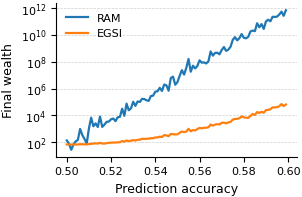

In [14]:
import numpy as np
import matplotlib as mpl
import matplotlib.pyplot as plt

# ---------- Styling (single-column) ----------
mpl.rcParams.update({
    "figure.figsize": (3.25, 2.2),  # ~ single-column width
    "font.size": 9,
    "axes.labelsize": 9,
    "xtick.labelsize": 8,
    "ytick.labelsize": 8,
    "legend.fontsize": 8,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "legend.frameon": False,
    "savefig.pad_inches": 0.02,
})

# ---------- Data ----------
# ticks should be monotone and readable on axis; adjust as needed
ticks = 0.5 + np.arange(len(plot_ram)) * 0.001

# ---------- Plot ----------
fig, ax = plt.subplots()

ax.plot(ticks, plot_ram,  linewidth=1.6, label="RAM")
ax.plot(ticks, plot_egsi, linewidth=1.6, label="EGSI")

ax.set_xlabel("Prediction accuracy")
ax.set_ylabel("Final wealth")
ax.set_yscale("log")

# subtle grid lines to aid reading (no custom colors)
ax.grid(axis="y", linestyle="--", linewidth=0.5, alpha=0.6)

ax.legend(loc="best", ncol=1)
fig.tight_layout()

fig.savefig("fig_ram_vs_egsi.pdf", format="pdf", bbox_inches="tight")  # insert this in Overleaf

#2. Part 2 - Real ML Model

##2.1) preparation

In [ ]:
!pip install lightgbm

In [ ]:
!pip -q install kaggle --upgrade

from google.colab import files, drive
uploaded = files.upload()          # choose kaggle.json
!mkdir -p ~/.kaggle
!mv kaggle.json ~/.kaggle/
!chmod 600 ~/.kaggle/kaggle.json

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 181.2/181.2 kB 3.9 MB/s eta 0:00:00


Saving kaggle.json to kaggle.json


In [ ]:
DATA_ROOT = "/content/sp500_raw"
!mkdir -p $DATA_ROOT
!kaggle datasets download andrewmvd/sp-500-stocks --unzip -p $DATA_ROOT

Dataset URL: https://www.kaggle.com/datasets/andrewmvd/sp-500-stocks
License(s): CC0-1.0
  0% 0.00/18.7M [00:00<?, ?B/s]
100% 18.7M/18.7M [00:00<00:00, 778MB/s]


##2.2) dataset

###a) pre processing

In [ ]:
import pathlib

insp1, insp2, insp3 = "sp500_companies.csv", "sp500_index.csv", "sp500_stocks.csv"

CSV_PATH = pathlib.Path("/content/sp500_raw/"+insp3)

# 1. Read a *small* sample first (fast, avoids OOM on huge files)
sample = pd.read_csv(CSV_PATH, nrows=5)
print("First five rows:\n", sample, "\n")

# 2. Inspect the full schema without loading the data
df_info = pd.read_csv(CSV_PATH, nrows=0)
print("Columns:", list(df_info.columns))

# 3. Load the full DataFrame (if size is reasonable)
df = pd.read_csv(CSV_PATH, parse_dates=True)

# 4. Quick overview
df.info()          # dtypes, non-null counts, memory footprint
print(df.describe(include="all").T.head())   # stats per column

# 5. Peek at unique values / missing ratios
for col in df.columns[:10]:                  # ⇐ limit to first 10
    nunique = df[col].nunique(dropna=True)
    missing = df[col].isna().mean()
    print(f"{col:<20} uniques={nunique:<7} missing={missing:>.2%}")

print(df[:20])

First five rows:
          Date Symbol  Adj Close  Close  High  Low  Open  Volume
0  2010-01-04    MMM        NaN    NaN   NaN  NaN   NaN     NaN
1  2010-01-05    MMM        NaN    NaN   NaN  NaN   NaN     NaN
2  2010-01-06    MMM        NaN    NaN   NaN  NaN   NaN     NaN
3  2010-01-07    MMM        NaN    NaN   NaN  NaN   NaN     NaN
4  2010-01-08    MMM        NaN    NaN   NaN  NaN   NaN     NaN 

Columns: ['Date', 'Symbol', 'Adj Close', 'Close', 'High', 'Low', 'Open', 'Volume']
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1891536 entries, 0 to 1891535
Data columns (total 8 columns):
 #   Column     Dtype  
---  ------     -----  
 0   Date       object 
 1   Symbol     object 
 2   Adj Close  float64
 3   Close      float64
 4   High       float64
 5   Low        float64
 6   Open       float64
 7   Volume     float64
dtypes: float64(6), object(2)
memory usage: 115.5+ MB
              count unique         top  freq       mean         std       min  \
Date        1891536   3768

In [ ]:
CSV_PATH  = pathlib.Path("/content/sp500_raw/sp500_stocks.csv")
DATE_COL  = "Date"
TICKER    = "Symbol"          # older snapshots use "Ticker"
PRICE_COL = "Adj Close"       # fallback to "Close" where missing

# ── 1  Load only the needed columns ────────────────────────────────────────────
use_cols = [DATE_COL, TICKER, PRICE_COL, "Close"]      # pick both, pick whichever exists
df_raw   = pd.read_csv(CSV_PATH, usecols=lambda c: c in use_cols,
                       parse_dates=[DATE_COL])

# choose Adjusted if available else Close
if PRICE_COL not in df_raw.columns:
    PRICE_COL = "Close"

# drop rows with no price at all (≈ 67 %)
df_raw = df_raw.dropna(subset=[PRICE_COL])

# ── 2  Compute price factors per ticker ────────────────────────────────────────
df_raw = df_raw.sort_values([TICKER, DATE_COL])
df_raw["factor"] = df_raw.groupby(TICKER)[PRICE_COL].pct_change().add(1.0)

# some tickers start later than others ⇒ first row factor = NaN
df_raw = df_raw.dropna(subset=["factor"])

# ── 3  Forward-fill occasional holiday gaps (optional) ─────────────────────────
# maximum gap tolerated = 5 business days
df_raw["factor_ffill"] = (
    df_raw
        .groupby(TICKER)["factor"]
        .transform(lambda s: s.fillna(method="ffill", limit=5))
)

# ── 4  Pivot to wide matrix and keep only fully-observed days & tickers ────────
df_wide = (
    df_raw.pivot(index=DATE_COL, columns=TICKER, values="factor_ffill")
          .astype("float32")
)

# drop columns (tickers) that still have NaNs
na_by_col = df_wide.isna().mean()
cols_keep = na_by_col[na_by_col == 0].index
df_wide   = df_wide[cols_keep]

# drop any day that now has a NaN (should be none, but safe-guard)
df_factor_clean = df_wide.dropna(axis=0, how="any").sort_index()

print("final shape =", df_factor_clean.shape)
print("any NaN left = ", df_factor_clean.isna().any().any())
# final shape ≈ (n_days, m_clean)   e.g. (3640, 485)

<ipython-input-36-83c06b319fa0>:30: FutureWarning: Series.fillna with 'method' is deprecated and will raise in a future version. Use obj.ffill() or obj.bfill() instead.
  .transform(lambda s: s.fillna(method="ffill", limit=5))
<ipython-input-36-83c06b319fa0>:27: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_raw["factor_ffill"] = (


final shape = (3767, 150)
any NaN left =  False


In [ ]:
print(df_factor_clean.describe(include="all").T.head())

         count      mean       std       min       25%       50%       75%  \
Symbol                                                                       
ABT     3767.0  1.000571  0.013512  0.902143  0.993946  1.000594  1.007652   
ADM     3767.0  1.000365  0.016334  0.758029  0.992638  1.000828  1.008962   
AES     3767.0  1.000290  0.020065  0.826989  0.990316  1.000778  1.010753   
AJG     3767.0  1.000861  0.012821  0.847648  0.994702  1.001112  1.007294   
ALB     3767.0  1.000603  0.025314  0.800894  0.989013  1.001058  1.012985   

             max  
Symbol            
ABT     1.109360  
ADM     1.102695  
AES     1.149582  
AJG     1.132327  
ALB     1.137381  


###b) post processing

In [ ]:
comp_a_names = ["T", "MSFT", "NVDA", "AMZN", "V"]
comp_b_names = ["CSCO", "MSFT",   # technology
                "WRB", "RF",      # financial
                "T", "NFLX",      # communication
                "SBUX", "BBY",    # consumer
                "ABT", "BAX"]     # healthcare
comp_c_names = ["CMCSA", "AMP", "HSIC", "FSLR", "FCX", "DE", "CE", "VLO", "BWA", "PH", "ANSS", "AMZN", "C", "EXPE", "FDX", "TJX", "WST", "EMN", "PGR", "FAST", "PODD", "HST", "ADM", "NVDA", "PAYX", "BRO", "MO", "ESS", "DTE", "WEC"]

comp_a_pre = df_factor_clean[comp_a_names]
comp_b_pre = df_factor_clean[comp_b_names]
comp_c_pre = df_factor_clean[comp_c_names]

time_A = [2150,2600] # [2400:2600]      2019-July to 2020-May
time_B = [3012,3767] # [3012,3767]      2022-December to 2024-December

a_A = comp_a_pre[time_A[0]:time_A[1]]
b_A = comp_b_pre[time_A[0]:time_A[1]]
c_A = comp_c_pre[time_A[0]:time_A[1]]
a_B = comp_a_pre[time_B[0]:time_B[1]]
b_B = comp_b_pre[time_B[0]:time_B[1]]
c_B = comp_c_pre[time_B[0]:time_B[1]]

In [ ]:
############## Sample Testing ########################
def ram_eg_ml(df, eta, ml_pred):
    n, m = df.shape
    # RAM init
    ram_wealth = 1.0
    weights = np.ones(m) / m

    # EG init
    weights_eg = np.full((m, m), 1.0 / m, dtype=np.float64)
    wealth_eg  = 1.0

    t = 0

    for _, row in df.iterrows():
        # clairvoyant return at i
        x = row.to_numpy(dtype=np.float64)

        # predicted return
        y_idx = ml_pred[t]
        # y_idx = forecast_perm(x, accuracy)
        y = np.array([x[j] for j in y_idx])
        s = y_idx[0]
        # permutation layer
        w_desc = np.sort(weights)[::-1]
        w_new = np.empty_like(weights)
        for rank, asset_idx in enumerate(y_idx):
            w_new[asset_idx] = w_desc[rank]
        # get wealth
        dR = w_new @ x
        ram_wealth *= dR
        # get new weights
        weights = (w_new * x) / dR

        ####### EG #########
        w_s      = weights_eg[s]
        port_ret = np.dot(w_s, x)
        wealth_eg  *= port_ret

        # Exponential-Gradient update
        w_s *= np.exp(eta * x / port_ret)
        w_s /= w_s.sum()

        t += 1

    return ram_wealth, wealth_eg

In [ ]:
def pure_ml(df, ml_pred):
    wealth = 1
    k = 0
    for _, row in df.iterrows():
        wealth *= row[ml_pred[k][0]]

        k+=1
    return wealth

##2.3) model training

In [ ]:
"""
sliding_rank_lgbm.py
--------------------
Produce daily cross-section ranks with LightGBM LambdaMART.

• sliding window  (RECENT_WINDOW days)
• exponential decay  (DECAY_GAMMA)
• integer relevance labels  (mandatory for ranking)
• warm-starts each booster for speed (init_model)

Returns
-------
start_day   : int    (date_idx of first prediction)
rank_matrix : ndarray, shape = (n - start_day, m)
"""

# ---------- 0. imports ----------
import pandas as pd
import numpy as np
import lightgbm as lgb
from pathlib import Path
from tqdm import trange

# ---------- 1. user-configurable ----------
N_LAGS        = 3        # lagged factors per asset
RECENT_WINDOW = 250      # training window length (days)
DECAY_GAMMA   = 0.995    # per-day exponential decay (1 → uniform)
VAL_DAYS      = 60       # inner validation slice for early stopping
N_TREES       = 300      # base num_boost_round
EARLY_STOP    = 20       # callback patience
VERBOSE_EVAL  = False    # LightGBM stdout

# ---------- 2. wide → long panel w/ lags & target ----------
def prepare_long(df_wide: pd.DataFrame, n_lags: int) -> pd.DataFrame:
    df = df_wide.copy()
    df["date_idx"] = np.arange(len(df))
    long = df.melt(id_vars="date_idx",
                   var_name="asset",
                   value_name="ret_t")           # ret_t is today's gross return

    for l in range(1, n_lags + 1):
        long[f"ret_lag{l}"] = long.groupby("asset")["ret_t"].shift(l)

    long["target_ret"] = long.groupby("asset")["ret_t"].shift(-1)
    long.dropna(inplace=True)
    long.reset_index(drop=True, inplace=True)
    return long

# ---------- 3. integer relevance labels per day ----------
def add_relevance(long: pd.DataFrame) -> pd.DataFrame:
    def _rank_int(s: pd.Series):
        # lowest return  -> 0,  highest -> m-1
        return (s.rank(method="first", ascending=True) - 1).astype(int)
    long["relevance"] = long.groupby("date_idx")["target_ret"].transform(_rank_int)
    return long

# ---------- 4. utility to build LightGBM Dataset ----------
def build_lgb_dataset(block: pd.DataFrame,
                      decay_gamma: float):
    feat_cols = [c for c in block.columns if c.startswith("ret_")]
    X, y = block[feat_cols], block["relevance"]

    group = block.groupby("date_idx").size().values
    age   = block["age"]
    wts   = (decay_gamma ** age).values
    return lgb.Dataset(X, y, group=group, weight=wts, free_raw_data=False), feat_cols

# ---------- 5. main pipeline ----------
def sliding_rank_predictions(df_factor_clean: pd.DataFrame):
    long = prepare_long(df_factor_clean, N_LAGS)
    long = add_relevance(long)

    m          = df_factor_clean.shape[1]
    max_day    = long["date_idx"].max()
    start_day  = max(RECENT_WINDOW, N_LAGS)          # first day that can be scored
    n_days_out = max_day - start_day + 1

    rank_matrix = np.empty((n_days_out, m), dtype=np.int16)

    booster     = None                               # warm-start handle
    feat_cols   = None

    # -------------------------------------------------------------
    for idx, day in enumerate(                        # daily loop
            trange(start_day, max_day + 1, ncols=80)):
        # --------  build sliding window  ------------------------
        win_start = day - RECENT_WINDOW
        win_mask  = long["date_idx"].between(win_start, day - 1)

        block        = long.loc[win_mask].copy()
        block["age"] = day - 1 - block["date_idx"]

        val_cut  = max(block["date_idx"].min(), day - VAL_DAYS)
        val_mask = block["date_idx"] >= val_cut
        trn_mask = ~val_mask

        dtrain, feat_cols = build_lgb_dataset(block.loc[trn_mask], DECAY_GAMMA)
        dvalid, _         = build_lgb_dataset(block.loc[val_mask], DECAY_GAMMA)

        params = dict(objective="lambdarank",
                      metric="ndcg",
                      learning_rate=0.05,
                      num_leaves=63,
                      min_data_in_leaf=30,
                      verbosity=-1)

        booster = lgb.train(
            params,
            dtrain,
            num_boost_round=N_TREES,
            valid_sets=[dvalid],
            init_model=booster,          # warm‑start
            callbacks=[
                lgb.early_stopping(EARLY_STOP, first_metric_only=True, verbose=False),
                lgb.log_evaluation(-1)
            ]
        )

        # --------  inference for current day  -------------------
        X_today  = long[long["date_idx"] == day][feat_cols]
        scores   = booster.predict(X_today,
                                   num_iteration=booster.best_iteration)
        rank_matrix[idx] = scores.argsort()[::-1]      # high→low


    return start_day, rank_matrix

In [ ]:
for dataset in [a_A, b_A, c_A, a_B, b_B, c_B]:

    _, rank_mat = sliding_rank_predictions(dataset)
    to_run = dataset.iloc[251:]

    best_w = best(to_run)
    gm_w = gm(to_run)
    ram_w, egsi_w = ram_eg_ml(to_run, 0.05, rank_mat.tolist())
    ml_w = pure_ml(to_run, rank_mat.tolist())

    print(f"Best: {best_w}\t GM: {gm_w}\t RAM: {ram_w}\t EGSI: {egsi_w}\t ML: {ml_w}")

100%|█████████████████████████████████████████| 199/199 [01:09<00:00,  2.86it/s]
<ipython-input-246-aaac90bc78eb>:5: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  wealth *= row[ml_pred[k][0]]


Best: 1.7333662099241787	 GM: 1.2061561346054077	 RAM: 1.2397790670660627	 EGSI: 1.2301902932977695	 ML: 1.305495262145996


100%|█████████████████████████████████████████| 199/199 [02:51<00:00,  1.16it/s]
<ipython-input-246-aaac90bc78eb>:5: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  wealth *= row[ml_pred[k][0]]


Best: 1.3587748578569965	 GM: 0.9534178376197815	 RAM: 1.0038427382621955	 EGSI: 0.9826716571848239	 ML: 1.6783100366592407


100%|█████████████████████████████████████████| 199/199 [05:19<00:00,  1.60s/it]
<ipython-input-246-aaac90bc78eb>:5: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  wealth *= row[ml_pred[k][0]]


Best: 1.7333662099241787	 GM: 0.8853138089179993	 RAM: 0.9151650356262963	 EGSI: 0.9246241413254339	 ML: 0.5327281355857849


... (3 outputs left out)

Best: 3.1531377311637616	 GM: 1.3003515005111694	 RAM: 1.3779589073517693	 EGSI: 1.3731261614127162	 ML: 0.5721277594566345


100%|█████████████████████████████████████████| 504/504 [45:07<00:00,  5.37s/it]

Best: 8.293215670107248	 GM: 1.4015233516693115	 RAM: 1.4930821532269538	 EGSI: 1.5013096825154844	 ML: 1.3915815353393555



<ipython-input-246-aaac90bc78eb>:5: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  wealth *= row[ml_pred[k][0]]


In [ ]:
Best: 1.733	 GM: 1.206	 RAM: 1.239	 EGSI: 1.230	 ML: 1.305
Best: 1.358	 GM: 0.953	 RAM: 1.003	 EGSI: 0.982	 ML: 1.678
Best: 1.733	 GM: 0.885	 RAM: 0.915	 EGSI: 0.924	 ML: 0.532
Best: 8.293	 GM: 2.470	 RAM: 2.512	 EGSI: 2.629	 ML: 1.676
Best: 3.153	 GM: 1.300	 RAM: 1.377	 EGSI: 1.373	 ML: 0.572
Best: 8.293	 GM: 1.401	 RAM: 1.493	 EGSI: 1.501	 ML: 1.391


##2.4) Statistics

In [ ]:
def get_dom(ml, gm, ram, egsi):
    ml_gain = (ml-gm)/gm
    ram_gain = (ram-gm)/ml_gain
    eg_gain = (egsi-gm)/ml_gain
    return ram_gain - eg_gain

a_A = get_dom(1.305, 1.206, 1.239, 1.230)
b_A = get_dom(1.678, 0.953, 1.003, 0.982)
print(a_A)
print(b_A)
print(f"c_A: ram-egsi gap {0.915/0.924}")
print(f"c_A: ram-eg dominance {(0.915-0.885)/0.885}")
print(f"a_B: {2.512/2.629}")
print(f"b_B: {1.377/1.373}")
print(f"c_B: {1.493/1.501}")
print((0.572-1.3)/1.3)
print((1.377-1.373)/1.373)
print((1.377-1.3)/1.3)